# FERPlus data preparation

Data source: https://github.com/microsoft/ferplus

In [1]:
import numpy as np, os, PIL.Image as Image, pandas as pd, cv2
os.chdir('..')

In [2]:
dataset_dir = os.path.join('data', 'datasets', 'emotion recognition', 'FERPlus')
os.path.exists(dataset_dir)

True

In [3]:
old_images_dir = os.path.join(dataset_dir, 'FER2013Plus', 'Images')
os.path.exists(old_images_dir)

True

In [4]:
old_labels_dir = os.path.join(dataset_dir, 'FER2013Plus', 'Labels')
os.path.exists(old_labels_dir)

True

In [5]:
new_images_dir = os.path.join(dataset_dir, 'Images')
os.makedirs(new_images_dir, exist_ok = True)

In [6]:
ferplus_to_affectnet_label_translation = {
    0 : 0,
    1 : 1,
    2 : 3,
    3 : 2,
    4 : 6,
    5 : 5,
    6 : 4
}

affectnet_to_ferplus_label_translation = {v : k for k, v in ferplus_to_affectnet_label_translation.items()}
permute_indices = [affectnet_to_ferplus_label_translation[i] for i in range(7)]
permute_indices

[0, 1, 3, 2, 6, 5, 4]

In [7]:
label_translation = {
    0 : 'neutral',
    1 : 'happiness',
    2 : 'sadness',
    3 : 'surprise',
    4 : 'fear',
    5 : 'disgust',
    6 : 'anger'
}

In [8]:
inverse_label_translation = {value : key for key, value in label_translation.items()}
inverse_label_translation

{'neutral': 0,
 'happiness': 1,
 'sadness': 2,
 'surprise': 3,
 'fear': 4,
 'disgust': 5,
 'anger': 6}

In [9]:
counter = 0
output_filenames = []
emotion_labels = []
emotions = {str(i) : [] for i in range(7)}
splits = []

for split in ['FER2013Train', 'FER2013Valid', 'FER2013Test']:
    split_images_dir = os.path.join(old_images_dir, split)
    split_labels_file = pd.read_csv(os.path.join(old_labels_dir, split, 'label.csv'), names = ['filename', 'x', 'neutral', 'happiness', 'surprise', 'sadness', 'anger', 'disgust', 'fear', 'contempt', 'unknown', 'nf'])
    for i in range(len(split_labels_file)):
        filename = split_labels_file['filename'].iloc[i]
        image_path = os.path.join(split_images_dir, filename)
        image = cv2.imread(image_path)
        image = cv2.resize(image, (112, 112), interpolation = cv2.INTER_CUBIC)
        output_filename = f'{counter}.png'
        output_filenames.append(output_filename)
        cv2.imwrite(os.path.join(new_images_dir, output_filename), image)

        labels = split_labels_file.iloc[i, 2:]
        labels = np.array(labels, dtype = np.uint8)
        permuted_labels = list(labels[permute_indices])
        emotion_label = np.argmax(permuted_labels)

        for j in range(len(permuted_labels)):
            emotions[str(j)].append(permuted_labels[j])
        emotion_labels.append(emotion_label)

        if 'Train' in split:
            splits.append('train')
        elif 'Test' in split:
            splits.append('test')
        else:
            splits.append('validation')

        counter += 1
            

In [10]:
labels_df = pd.DataFrame(
    data = {
        'filename' : output_filenames,
        'label' : emotion_labels,
        **emotions,
        'split' : splits
    }
)

labels_df.to_csv(os.path.join(dataset_dir, 'labels.csv'), index = False)

# EDA

In [11]:
from matplotlib import pyplot as plt

In [12]:
labels_df = pd.read_csv(os.path.join(dataset_dir, 'labels.csv'))

In [13]:
np.unique(labels_df['split'], return_counts = True)

(array(['test', 'train', 'validation'], dtype=object),
 array([ 3573, 28558,  3579]))

In [14]:
labels_df.head()

,filename,label,0,1,2,3,4,5,6,split
0,0.png,0,4,0,1,0,0,2,3,train
1,1.png,0,6,0,1,1,0,0,0,train
2,2.png,0,5,0,3,0,0,0,1,train
3,3.png,0,4,0,4,0,0,0,1,train
4,4.png,0,9,0,1,0,0,0,0,train


In [15]:
emotions = [0, 1, 2, 3, 4, 5, 6]
emotions = [label_translation[emotion] for emotion in emotions]
emotion_counts = np.sum(labels_df[['0', '1', '2', '3', '4', '5', '6']], 0) / 10

sorted_indices = np.argsort(emotion_counts)
emotions = [emotions[i] for i in sorted_indices]
emotion_counts = emotion_counts[sorted_indices]

/tmp/ipykernel_1264805/393771072.py:7: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  emotion_counts = emotion_counts[sorted_indices]


In [16]:
figures_output_dir = os.path.join('data', 'figures', 'Emotion Recognition', 'FERPlus')
os.makedirs(figures_output_dir, exist_ok = True)

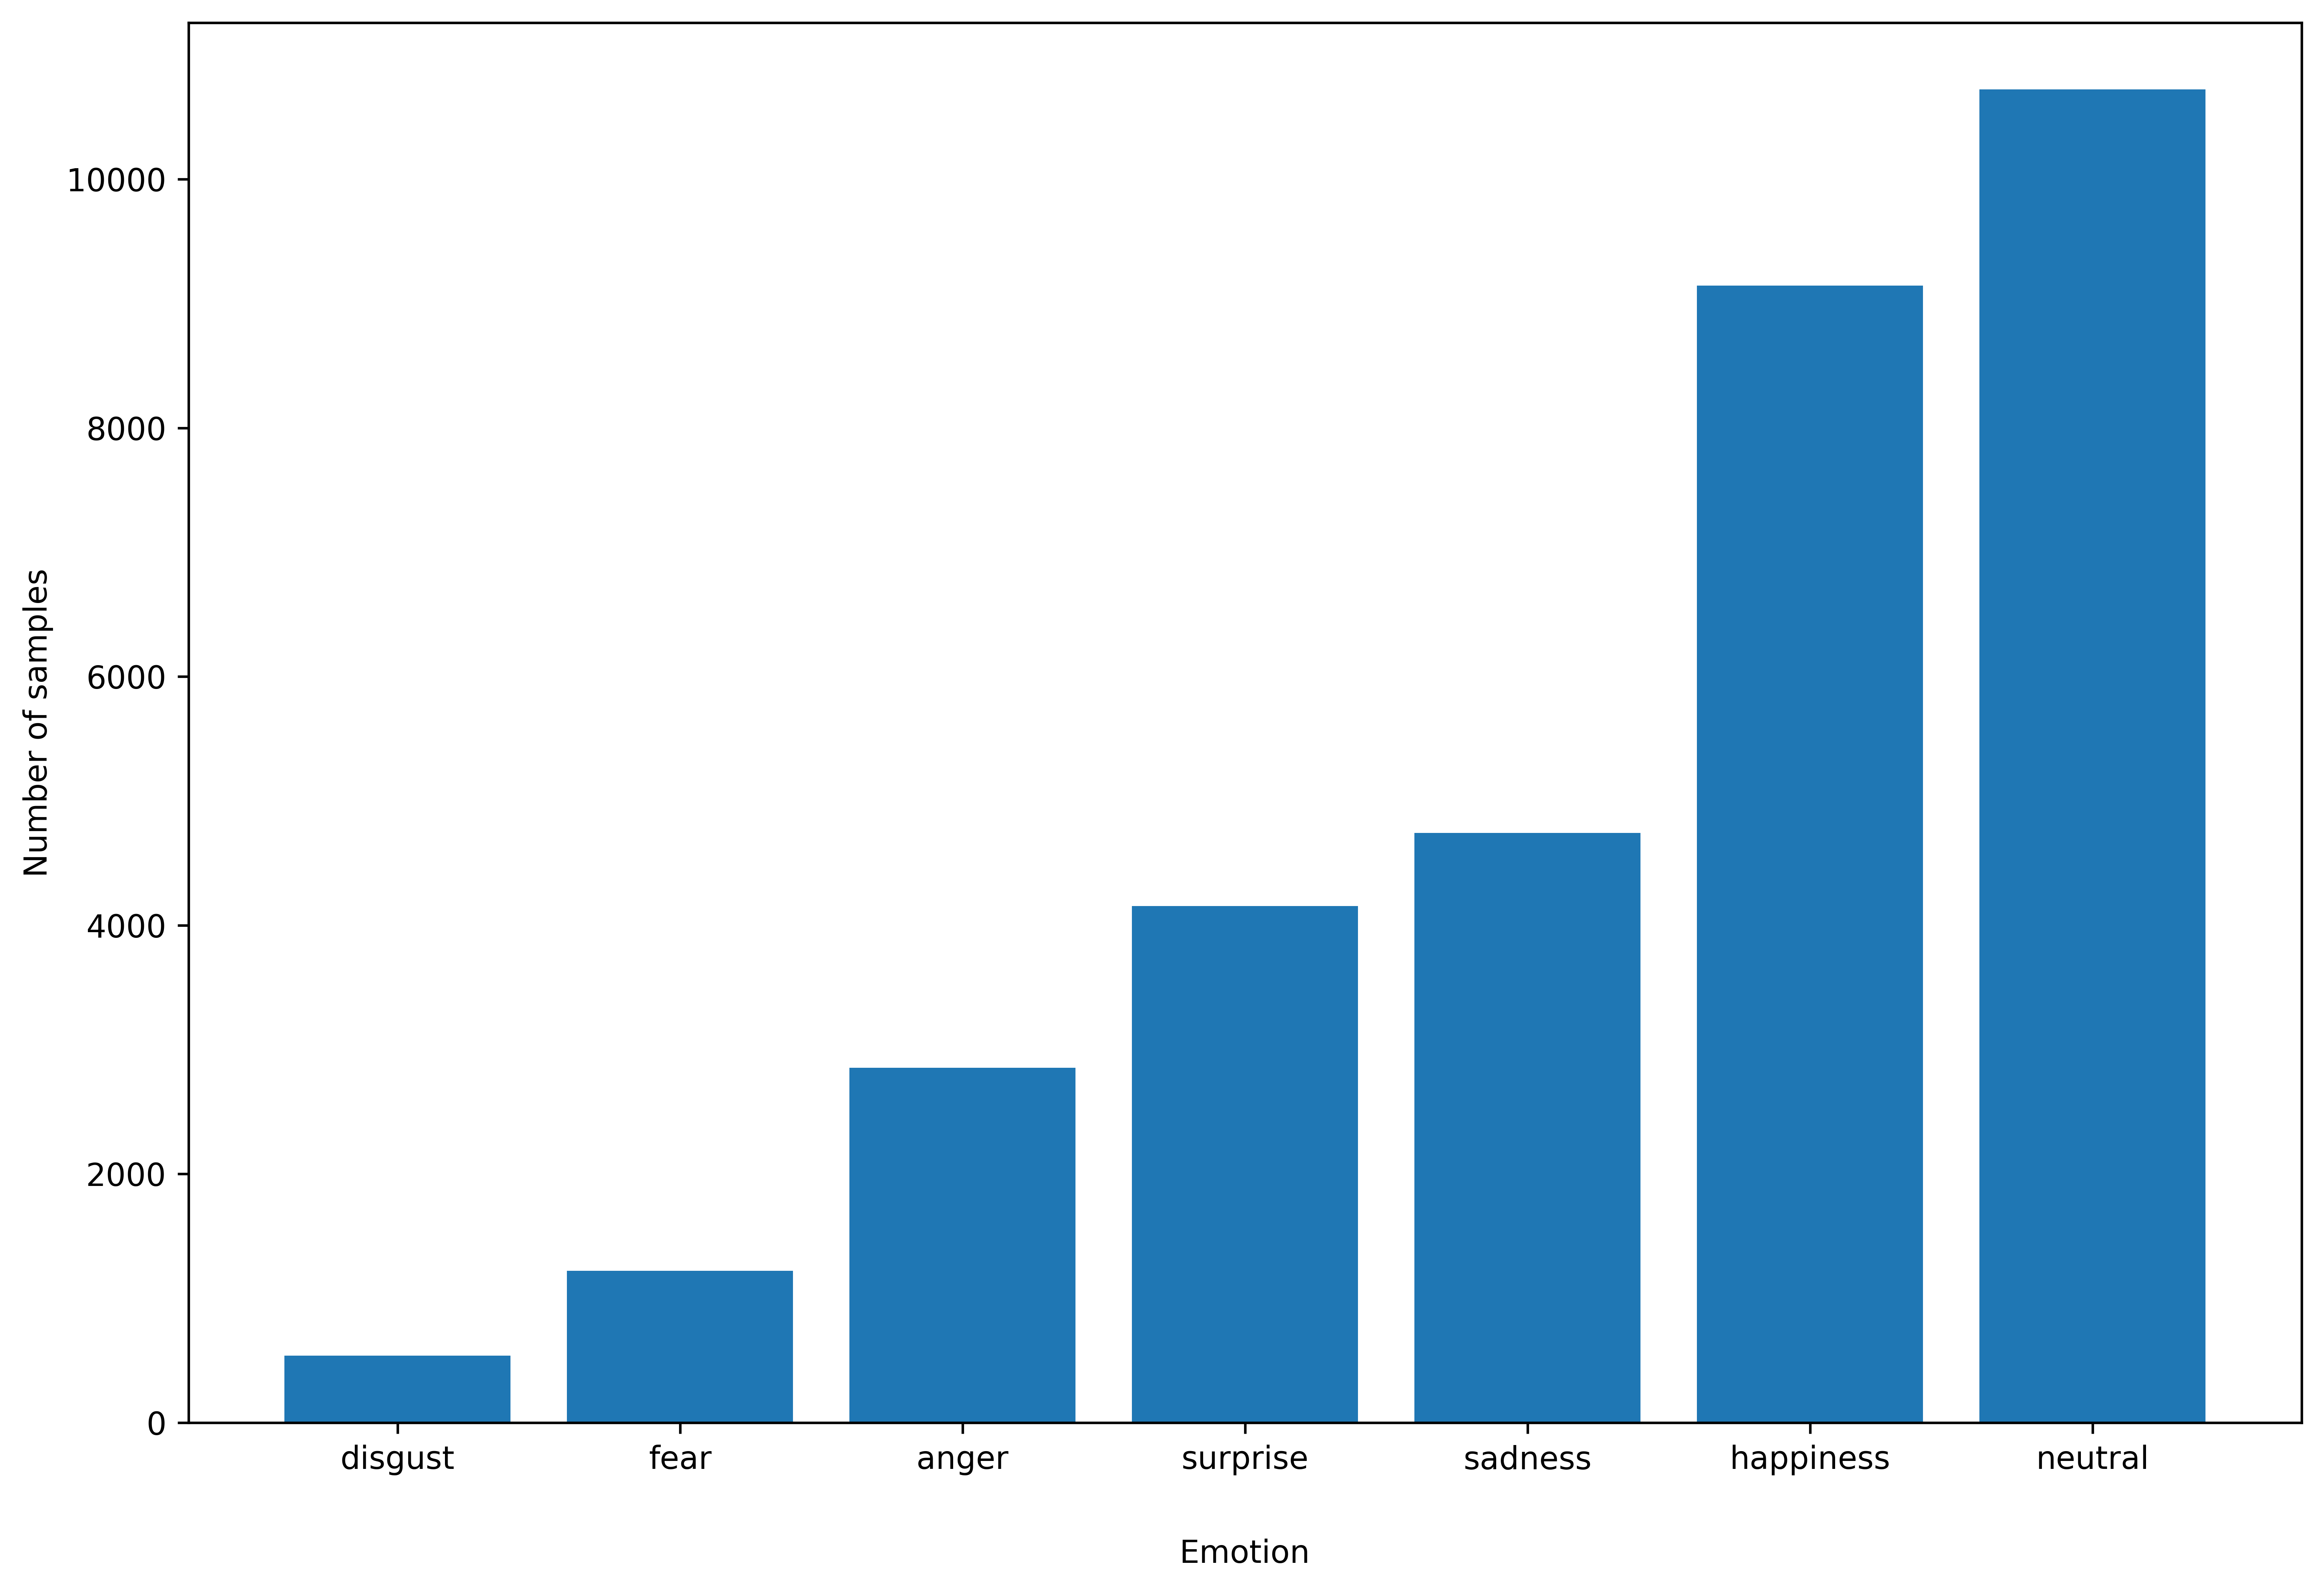

In [17]:
plt.figure(figsize = (12, 8), dpi = 600)
plt.bar(x = emotions, height = emotion_counts)
plt.xlabel('Emotion', labelpad = 20)
plt.ylabel('Number of samples')
plt.savefig(
    os.path.join(figures_output_dir, 'The distribution of emotions in FERPlus')
)
plt.show()

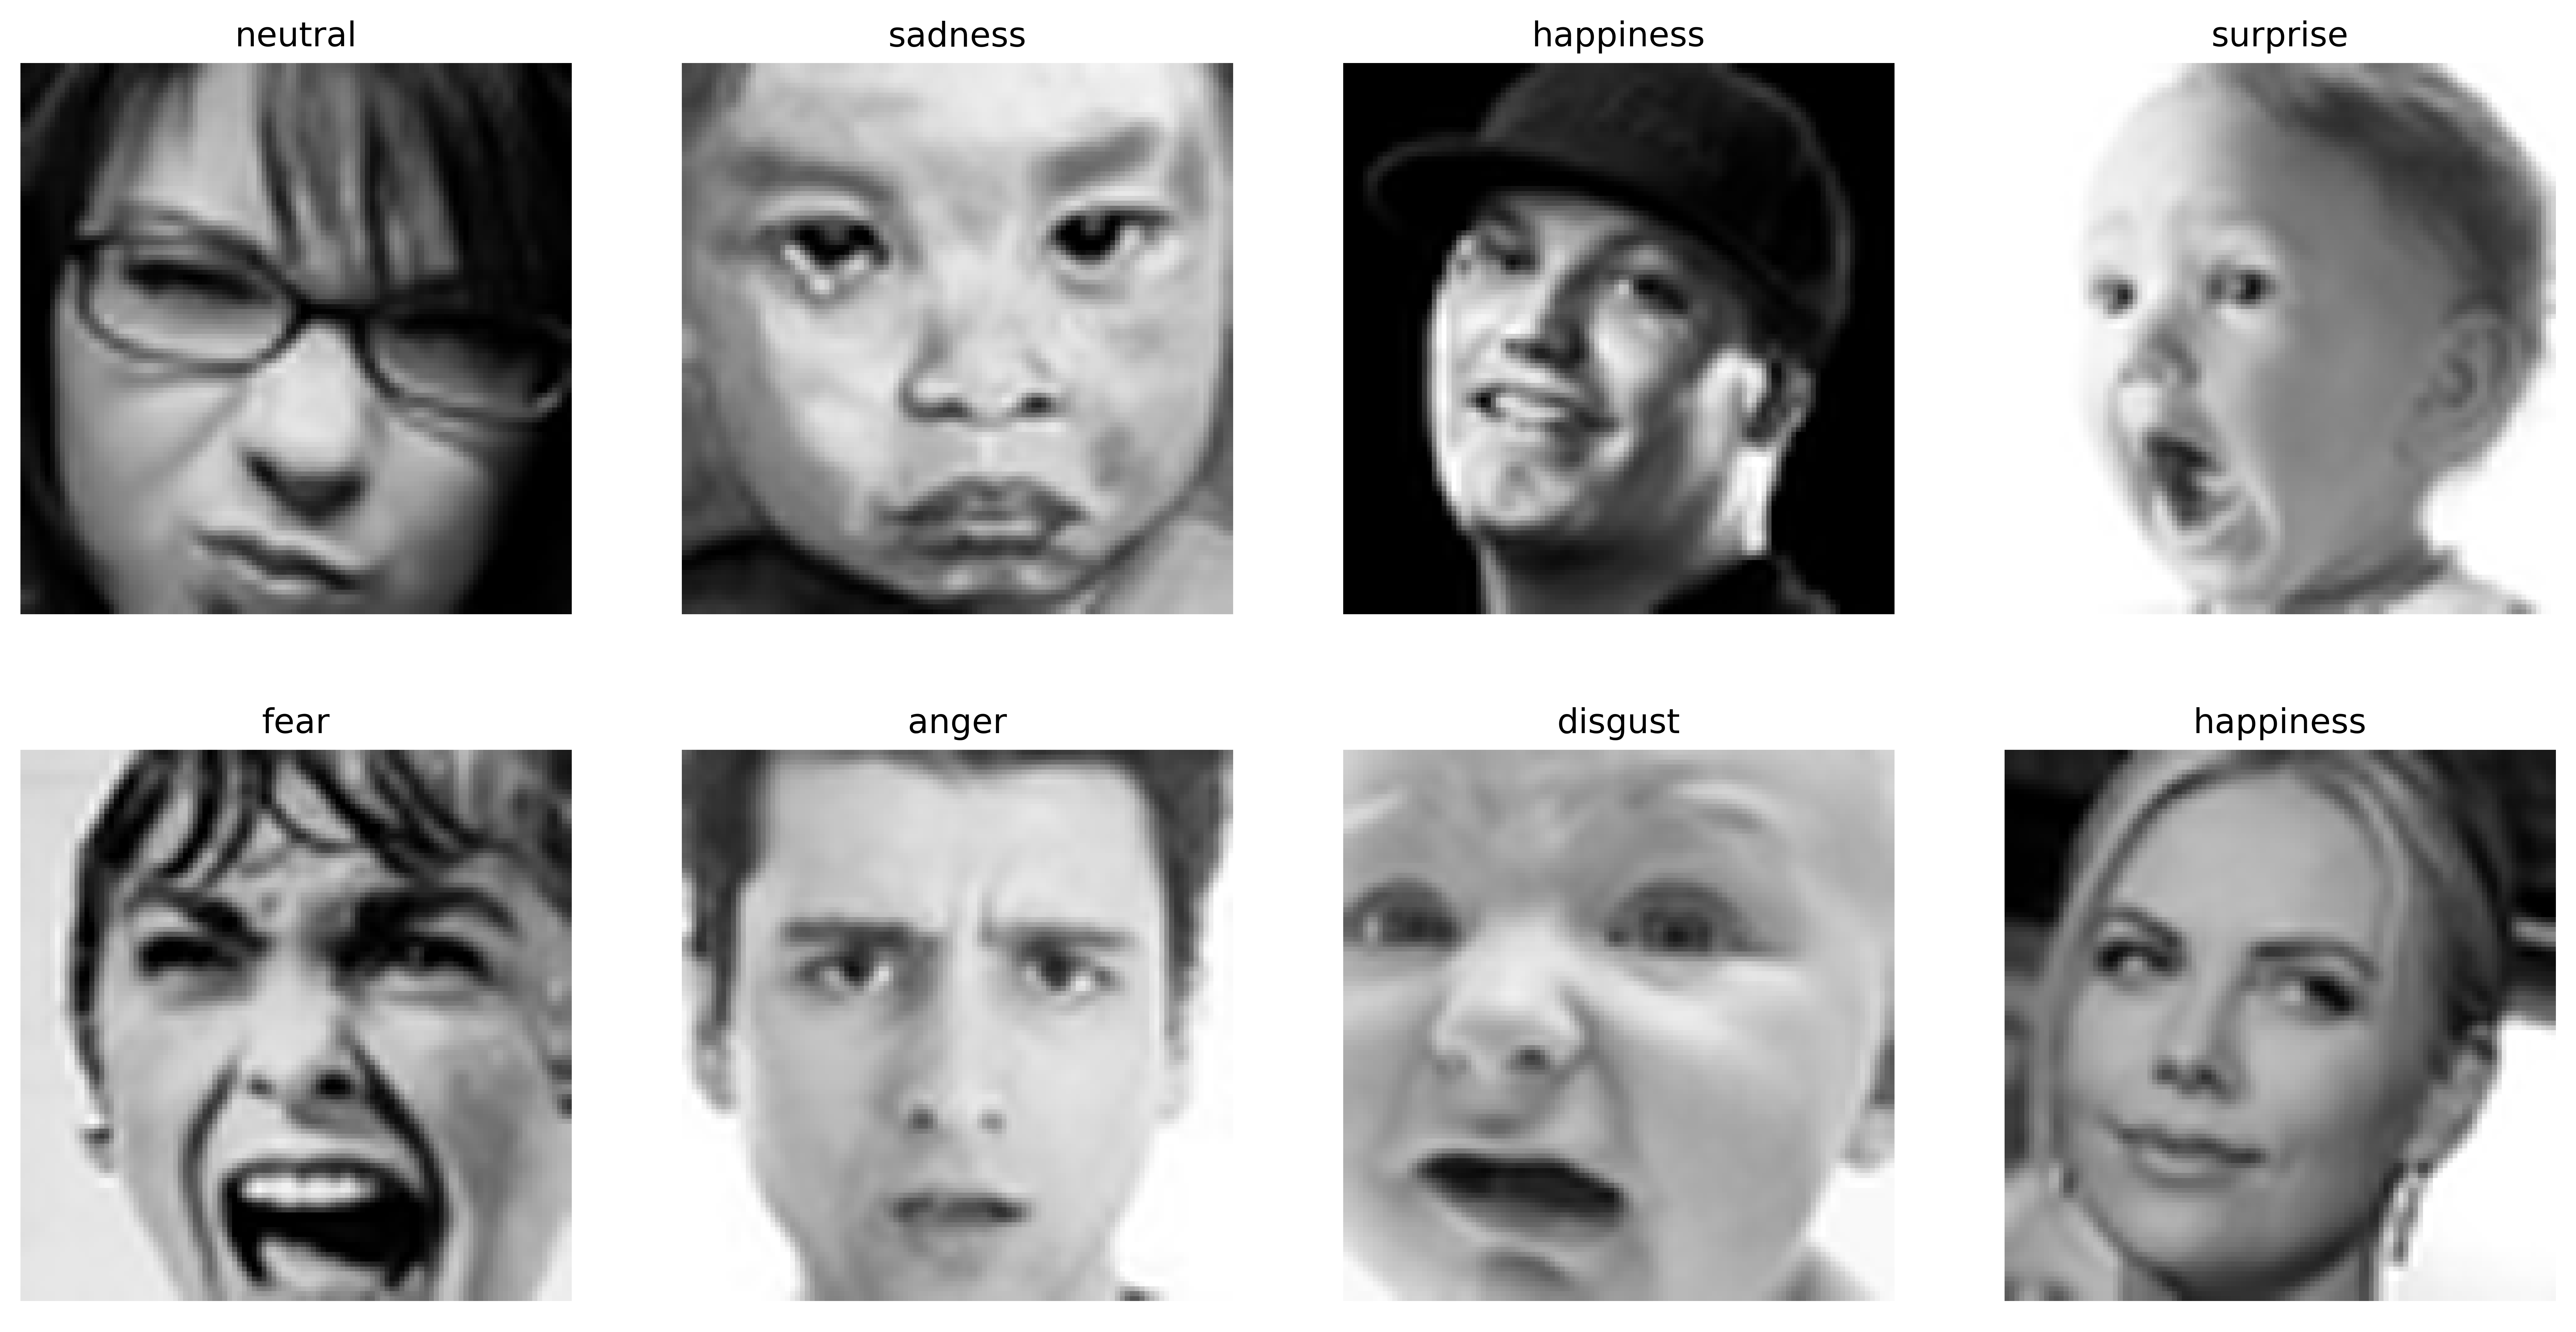

In [18]:
plt.figure(figsize = (16, 8), dpi = 600)
plt.axis('off')

shown_emotions = []
for i in range(8):
    index = np.random.randint(low = 0, high = len(labels_df))
    emotion = labels_df.iloc[index][['0', '1', '2', '3', '4', '5', '6']]
    emotion = np.argmax(emotion)

    while emotion in shown_emotions:
        index = np.random.randint(low = 0, high = len(labels_df))
        emotion = labels_df.iloc[index][['0', '1', '2', '3', '4', '5', '6']]
        emotion = np.argmax(emotion)

        if len(shown_emotions) == 7:
            break
    shown_emotions.append(emotion)

    image_path = os.path.join(new_images_dir, labels_df.iloc[index]['filename'])
    image = cv2.imread(image_path, cv2.IMREAD_COLOR_RGB)
    plt.subplot(2, 4, i+1)
    plt.imshow(image)
    plt.title(f'{label_translation[emotion]}')
    plt.axis('off')
plt.savefig(
    os.path.join(figures_output_dir, 'Sample images from FERPlus')
)
plt.show()